# Perturbed iNeuron DEGs

In [1]:
import re
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import scvelo as scv
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse import issparse
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests


In [2]:
adata_xenium = sc.read_10x_h5(
    filename="path/to/file/cell_feature_matrix.h5"
)


In [3]:
adata_xenium.obs['total_counts'] = adata_xenium.X.sum(axis=1).A1
num_cells_800 = (adata_xenium.obs['total_counts'] >= 800).sum()
adata_filtered = adata_xenium[adata_xenium.obs['total_counts'] >= 800].copy()
sgRNA_genes = [gene for gene in adata_filtered.var_names if '-' in gene and not 'HLA' in gene]
sgRNA_to_target = {sg: sg.split('-')[0] for sg in sgRNA_genes}

idxs = [adata_filtered.var_names.get_loc(g) for g in sgRNA_genes]
mat = adata_filtered.X[:, idxs]
if issparse(mat):
    mat = mat.toarray()
bin_mat = (mat > 1).astype(int)
df_ind = pd.DataFrame(
    bin_mat,
    index=adata_filtered.obs_names,
    columns=[g for g in sgRNA_genes]
)
adata_filtered.obs = adata_filtered.obs.join(df_ind)

obs_clean = adata_filtered.obs.drop(columns=["total_counts"], errors="ignore")
gene_cols = [g for g in sgRNA_genes if g in obs_clean.columns]

counts = obs_clean[gene_cols].sum(axis=0).sort_values(ascending=False)
counts_df = pd.DataFrame({
    "gene":  counts.index,
    "count": counts.values
})
counts_df["rank"] = counts_df["count"].rank(ascending=False, method="dense")

top4 = counts_df.loc[:3, 'gene'].tolist()
top2 = counts_df.loc[:1, 'gene'].tolist()
remaining = [
    col for col in adata_filtered.obs.columns
    if col not in top2 + ['total_counts']
]
adata_filtered.obs['sgRNA_Gene_count'] = (
    adata_filtered.obs[remaining].sum(axis=1)
)
adata_filtered.obs.drop(columns=top2, inplace=True)
adata_filtered.obs['unperturbed'] = np.where(
    adata_filtered.obs['sgRNA_Gene_count'] > 0,
    0,
    1
)


In [4]:
obs = adata_filtered.obs[remaining]
sgRNA_cols = [col for col in obs.columns if "-" in col]

gene_names = sorted({col.split("-", 1)[0] for col in sgRNA_cols})
perturb_df = pd.DataFrame(index=obs.index, columns=gene_names, dtype="object")

for gene in gene_names:
    matching_cols = [col for col in sgRNA_cols if col.startswith(gene + "-")]
    if not matching_cols:
        continue

    sub_df = obs[matching_cols]
    any_positive = (sub_df > 0).any(axis=1)
    perturb_df[gene] = any_positive.map({True: 1, False: 0})
for gene in gene_names:
    colname = f"{gene}"
    adata_filtered.obs[colname] = perturb_df[gene]


In [5]:
adata_gene = adata_filtered.copy()


In [6]:
cols_to_drop = [col for col in adata_gene.obs.columns if '-' in col]
adata_gene.obs.drop(columns=cols_to_drop, inplace=True)


In [7]:
adata_gene.obs.drop(columns=['total_counts'], inplace=True)
adata_gene.obs.drop(columns=['sgRNA_Gene_count'], inplace=True)


In [8]:
probes_to_remove = [
    'AFF1-1', 'AFF1-2', 'AFF1-3', 'AFF1-4',
    'BCL6-1', 'BCL6-2', 'BCL6-3', 'BCL6-4', 'BCL6-5',
    'BNC2-1', 'BNC2-2', 'BNC2-3', 'BNC2-4', 'BNC2-5',
    'CARHSP1-1', 'CARHSP1-2', 'CARHSP1-3', 'CARHSP1-4', 'CARHSP1-5',
    'CREB5-1', 'CREB5-2', 'CREB5-3', 'CREB5-4', 'CREB5-5',
    'EBF1-1', 'EBF1-2', 'EBF1-3', 'EBF1-4', 'EBF1-5',
    'EBF3-1', 'EBF3-2', 'EBF3-3', 'EBF3-4', 'EBF3-5',
    'HMGB2-1', 'HMGB2-2', 'HMGB2-3', 'HMGB2-4', 'HMGB2-5',
    'ID2-1', 'ID2-2', 'ID2-3', 'ID2-4', 'ID2-5',
    'ID4-1', 'ID4-2', 'ID4-3', 'ID4-4', 'ID4-5',
    'ISL1-1', 'ISL1-2', 'ISL1-3', 'ISL1-4', 'ISL1-5',
    'JUNB-1', 'JUNB-2', 'JUNB-3', 'JUNB-4', 'JUNB-5',
    'KLF3-1', 'KLF3-2', 'KLF3-3', 'KLF3-4', 'KLF3-5',
    'LHX9-1', 'LHX9-3', 'LHX9-4', 'LHX9-5',
    'MEIS2-1', 'MEIS2-2', 'MEIS2-3', 'MEIS2-4', 'MEIS2-5',
    'NFE2L2-1', 'NFE2L2-2', 'NFE2L2-3', 'NFE2L2-4', 'NFE2L2-5',
    'NFIB-1', 'NFIB-2', 'NFIB-3', 'NFIB-4', 'NFIB-5',
    'Negative_control-1', 'Negative_control-2', 'Negative_control-3', 'Negative_control-4', 'Negative_control-5',
    'ONECUT1-1', 'ONECUT1-2', 'ONECUT1-3', 'ONECUT1-4', 'ONECUT1-5',
    'ONECUT2-1', 'ONECUT2-2', 'ONECUT2-3', 'ONECUT2-4', 'ONECUT2-5',
    'PROX1-1', 'PROX1-2', 'PROX1-3', 'PROX1-5',
    'RUNX1-1', 'RUNX1-2', 'RUNX1-3', 'RUNX1-4', 'RUNX1-5',
    'SIX1-1', 'SIX1-2', 'SIX1-3', 'SIX1-4', 'SIX1-5',
    'SOX5-1', 'SOX5-2', 'SOX5-3', 'SOX5-4', 'SOX5-5',
    'ZBTB7C-1', 'ZBTB7C-2', 'ZBTB7C-3', 'ZBTB7C-4', 'ZBTB7C-5'
]
to_remove = [p for p in probes_to_remove if p in adata_gene.var_names]
keep_vars = [v for v in adata_gene.var_names if v not in to_remove]
adata_gene_clean = adata_gene[:, keep_vars].copy()


In [9]:
keep_genes = [g for g in adata_gene_clean.var_names if not re.search(r'-\d+$', g)]
adata_gene_clean = adata_gene_clean[:, keep_genes].copy()


In [10]:
scv.pp.normalize_per_cell(adata_gene_clean)
scv.pp.log1p(adata_gene_clean)


Normalized count data: X.
<cell 10>:2: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.


In [11]:
adata = adata_gene_clean.copy()


Genes significant (raw  p <= 0.05): 180
Genes significant (Bonf p <= 0.05): 96
Genes significant (FDR  p <= 0.05): 163


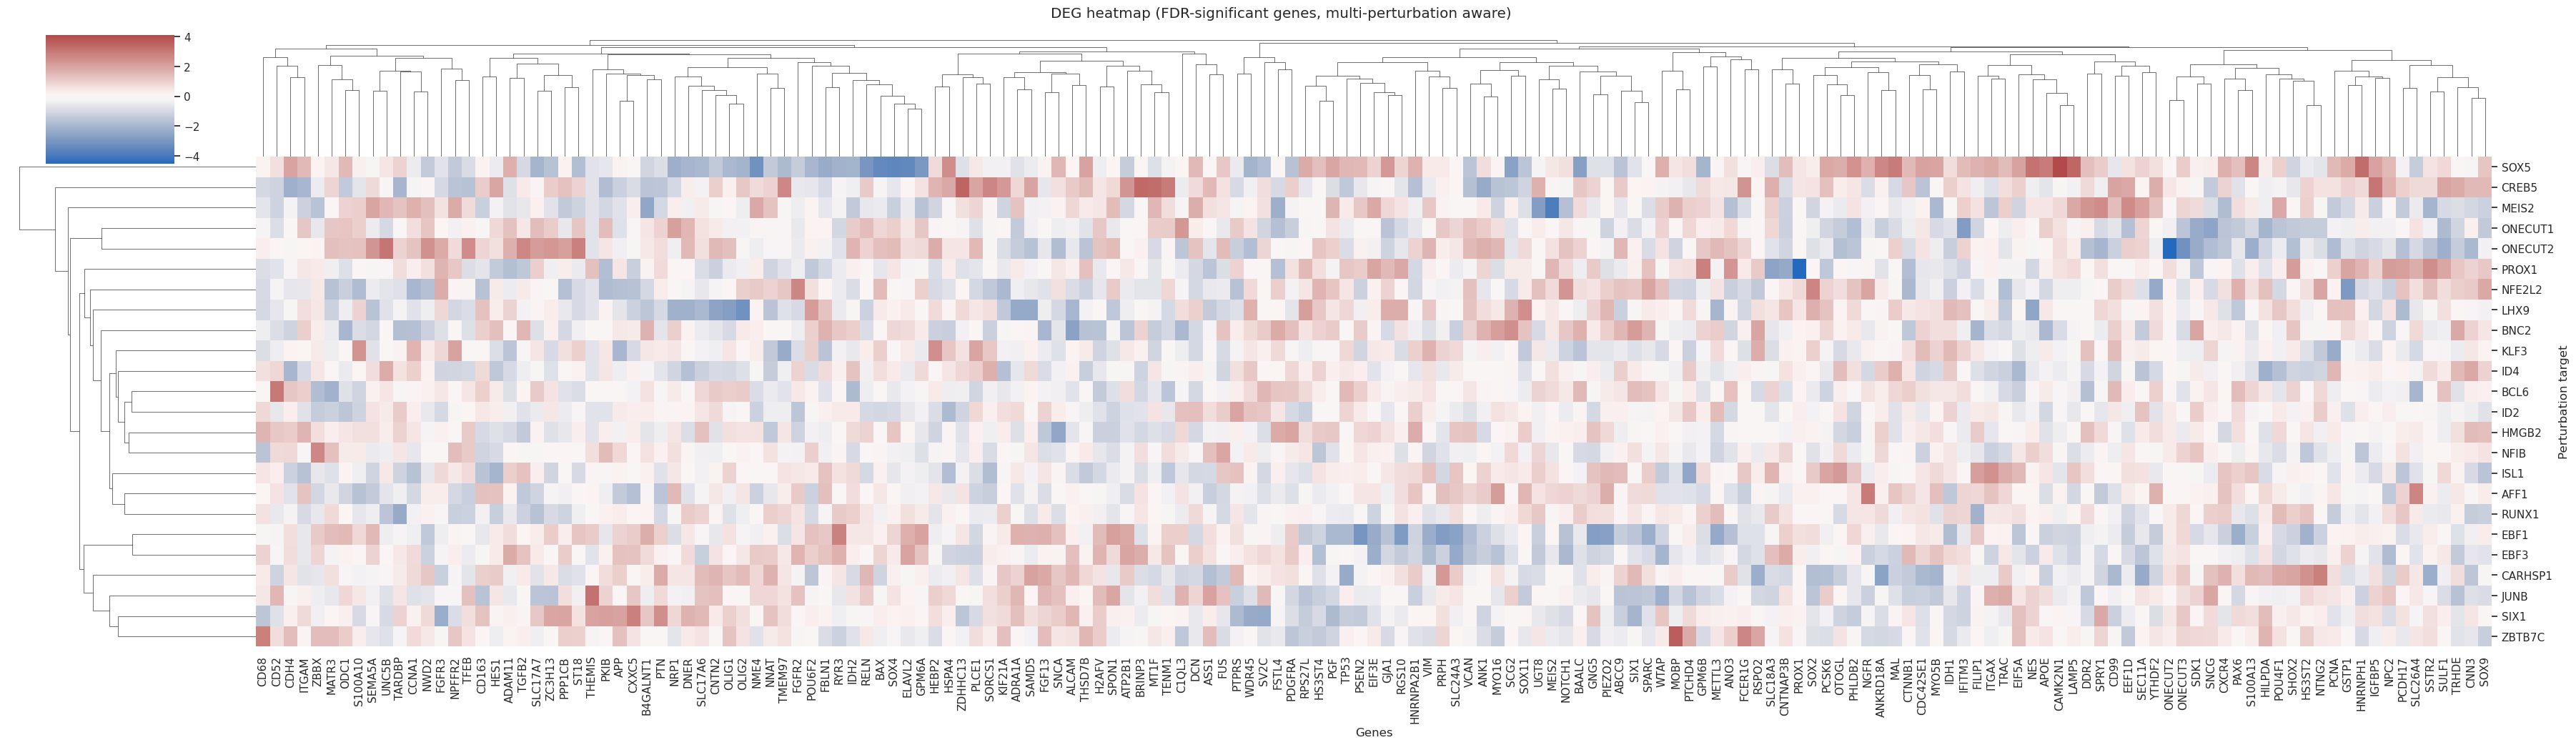

In [12]:
exclude   = {'unperturbed', 'Negative_control'}
pert_cols = [
    c for c in adata_gene_clean.obs.columns
    if c not in exclude and adata_gene_clean.obs[c].dtype.kind in ('i','b','u')
]
X = adata.X
if sparse.issparse(X):
    X = X.toarray()
else:
    X = np.asarray(X)

genes = adata.var_names

lfc = pd.DataFrame(index=pert_cols, columns=genes, dtype=float)

ctrl_mask = adata_gene_clean.obs["Negative_control"] == 1

for pert in pert_cols:
    pert_mask = adata_gene_clean.obs[pert] == 1

    # require minimum cells
    if pert_mask.sum() < 10 or ctrl_mask.sum() < 10:
        continue

    mu_p = X[pert_mask, :].mean(axis=0)
    mu_c = X[ctrl_mask, :].mean(axis=0)

    lfc.loc[pert] = mu_p - mu_c

from scipy.stats import kruskal

all_groups = pert_cols + ["Negative_control","unperturbed"]
pvals_omni = pd.Series(index=genes, dtype=float)

for i, gene in enumerate(genes):
    expr_lists = []

    for grp in all_groups:
        mask = adata_gene_clean.obs[grp] == 1
        vals = X[mask, i]
        if vals.size > 0:
            expr_lists.append(vals)

    if len(expr_lists) < 2:
        pvals_omni[gene] = np.nan
    else:
        _, p = kruskal(*expr_lists, nan_policy="omit")
        pvals_omni[gene] = p

pvals_omni.dropna(inplace=True)

alpha  = 0.05
p_flat = pvals_omni.values

_, bonf_flat, _, _ = multipletests(p_flat, alpha=alpha, method="bonferroni")
_, fdr_flat,  _, _ = multipletests(p_flat, alpha=alpha, method="fdr_bh")

bonf_omni = pd.Series(bonf_flat, index=pvals_omni.index)
fdr_omni  = pd.Series(fdr_flat,  index=pvals_omni.index)

sig_raw  = pvals_omni.index[pvals_omni  <= alpha]
sig_bonf = bonf_omni.index[bonf_omni    <= alpha]
sig_fdr  = fdr_omni.index[fdr_omni      <= alpha]

print(f"Genes significant (raw  p <= {alpha}): {len(sig_raw)}")
print(f"Genes significant (Bonf p <= {alpha}): {len(sig_bonf)}")
print(f"Genes significant (FDR  p <= {alpha}): {len(sig_fdr)}")

sig_genes_fdr = list(sig_fdr)
sig_genes_bonf = list(sig_bonf)
sig_genes_raw = list(sig_raw)
df_sig = pd.DataFrame({
    'p_raw':  pvals_omni.loc[sig_genes_fdr],
    'p_bonf': bonf_omni.loc[sig_genes_fdr],
    'p_fdr':  fdr_omni.loc[sig_genes_fdr],
})

sig_genes = list(fdr_omni.index[fdr_omni <= alpha])

plot_df = lfc[sig_genes].dropna(axis=1, how="all")

plot_df_z = (
    plot_df
    .subtract(plot_df.mean(axis=0), axis=1)
    .div(plot_df.std(axis=0),   axis=1)
)

sns.set(context="notebook", style="white")

cg = sns.clustermap(
    plot_df_z,
    cmap="vlag",
    center=0,
    row_cluster=True,
    col_cluster=True,
    figsize=(36, 10),
    xticklabels=1,
    yticklabels=1,
    dendrogram_ratio=(.1, .2),
    cbar_pos=(0.02, .8, .05, .18)
)

cg.ax_heatmap.set_xlabel("Genes")
cg.ax_heatmap.set_ylabel("Perturbation target")
plt.suptitle("DEG heatmap (FDR-significant genes, multi-perturbation aware)", y=1.02)
plt.show()
